# Brain MRI tumour classification (BRISC 2025) — educational prototype

**Problem.** Given one T1-weighted brain MRI slice, predict exactly one of four classes —
`glioma`, `meningioma`, `pituitary`, `no_tumor` — with a single four-class CNN trained **from
randomly initialised weights** (no transfer learning, no pretrained parts, no hosted models).
The user-facing tumour status is *derived* from that one output:

* `no_tumor` → "No tumor detected in this image."
* any other class → "Tumor detected — predicted type: [class]."

The confidence shown is the model's softmax score, **not** a clinical probability. This is an
educational prototype, not a diagnostic service.

**How this notebook is organised.** All reusable logic lives in `src/` and `utils/` and is
imported here; the notebook only orchestrates, displays and interprets. Sections:
1 provenance · 2 cleaning · 3 splitting · 4 exploration · 5 preprocessing · 6 models ·
7 training · 8 evaluation · 9 prediction functions & examples · 10 limitations · 11 reproducibility.

In [1]:
%matplotlib inline
import json
import os
import platform
import sys
from pathlib import Path

os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
ROOT = Path.cwd().resolve()
ROOT = ROOT.parent if ROOT.name == "notebook" else ROOT
sys.path.insert(0, str(ROOT))

import keras
import numpy as np
import pandas as pd
import tensorflow as tf

from config.settings import get_settings, load_pipeline_config
from src import plots
from src.labels import CLASS_NAMES, tumor_status_message
from src.registry import ModelRegistry

pd.set_option("display.max_colwidth", 120)
settings = get_settings()
config = load_pipeline_config()
registry = ModelRegistry(settings.models_dir)
print(f"Python {platform.python_version()} | TensorFlow {tf.__version__} | Keras {keras.__version__} | NumPy {np.__version__}")
print("Compute devices:", [d.device_type for d in tf.config.list_physical_devices()], "| CPU:", platform.processor())
print("Class order = model output indices:", CLASS_NAMES)

Python 3.13.2 | TensorFlow 2.20.0 | Keras 3.15.1 | NumPy 2.5.5
Compute devices: ['CPU'] | CPU: Intel64 Family 6 Model 140 Stepping 1, GenuineIntel
Class order = model output indices: ('glioma', 'meningioma', 'pituitary', 'no_tumor')


## 1. Dataset provenance

* **Source:** BRISC 2025 — Fateh et al., *Scientific Data* 13, 361 (2026), doi:10.1038/s41597-026-06753-y;
  preprint arXiv:2506.14318. Official host: Kaggle `briscdataset/brisc2025`.
* **Licence:** the ZIP contains **no licence file**. The official Kaggle page states
  *Attribution 4.0 International (CC BY 4.0)* (checked 2026-11-21); the arXiv paper is also CC BY 4.0.
  Still unverified: that this ZIP is byte-identical to the Kaggle release, and the terms of the
  upstream collections BRISC was built from (see README, *Dataset licence and attribution*).
* The supplied ZIP is opened **read-only**; its SHA-256 is recorded so the exact input is traceable.

The preparation pipeline (`scripts/prepare_dataset.py`) was run once before this notebook; set
`RUN_PREPARATION = True` to re-run it here (≈1 minute; rewrites `data/`).

In [2]:
RUN_PREPARATION = False
if RUN_PREPARATION:
    from src.dataset.prepare import prepare_dataset
    prepare_dataset(Path(os.environ["BRISC_ARCHIVE"]), settings, config)

card = json.loads((settings.manifests_dir / "dataset_card.json").read_text())
pd.Series({
    "dataset version": card["dataset_version"],
    "source": card["source"],
    "archive file": card["archive"]["filename"],
    "archive SHA-256": card["archive"]["sha256"],
    "archive size (bytes)": card["archive"]["bytes"],
    "manifest sidecar checksums match": card["manifest_checks"]["sidecar_checksums_match"],
    "manifest.csv and manifest.json agree": card["manifest_checks"]["csv_and_json_agree"],
    "manifest consistency issues": card["manifest_checks"]["issues"],
    "prepared at (UTC)": card["created_at"],
}).to_frame("value")

,value
dataset version,brisc2025-clean-v1
source,"BRISC 2025 — Fateh et al., Scientific Data 13, 361 (2026), doi:10.1038/s41597-026-06753-y; Kaggle briscdataset/brisc..."
archive file,archive (6).zip
archive SHA-256,edc2295d0eb6be19aa4ecee74974db0efbb5e088ddcdfde5229e3e2bfb0d010b
archive size (bytes),262284213
manifest sidecar checksums match,"{'manifest.csv': True, 'manifest.json': True}"
manifest.csv and manifest.json agree,True
manifest consistency issues,0
prepared at (UTC),2026-11-21T10:59:55+00:00


## 2. Data acquisition and cleaning

For every classification image the pipeline (`src/dataset/`):

1. checks the manifest row against the archive path, folder label, filename code and split;
2. reads the bytes (bounded), verifies the manifest SHA-256, and decodes by **content**;
3. fingerprints the image: SHA-256 of the decoded greyscale pixels (exact identity), a 64-bit DCT
   perceptual hash, and a 64×64 letterboxed thumbnail;
4. groups identical pixels (exact duplicates), keeps one representative, and would reject all copies if
   their labels disagreed;
5. finds near-duplicate candidates by perceptual-hash distance and confirms them with thumbnail correlation.

Segmentation copies and masks are **not** counted as extra images.

In [3]:
counts = card["counts"]
summary = pd.Series({k: v for k, v in counts.items() if not isinstance(v, dict)}).to_frame("value")
display(summary)
print("By label:", counts["by_label"])
print("By original split:", counts["by_original_split"])
print("Rejected by reason:", counts["rejected_by_reason"])
print("Similar pairs by kind:", counts["similar_pairs_by_kind"])
print("Segmentation task:", card["segmentation_task"])

,value
classification_files,6000
decoded_and_checksum_ok,6000
exact_duplicate_groups,134
exact_groups_crossing_original_split,98
exact_groups_with_conflicting_labels,0
retained_unique_images,5856
meets_minimum_unique_images,True
linked_groups,647
images_in_linked_groups,1930
largest_linked_group,9


By label: {'glioma': 1401, 'meningioma': 1635, 'no_tumor': 1207, 'pituitary': 1757}
By original split: {'test': 1000, 'train': 5000}
Rejected by reason: {'exact_duplicate': 144}
Similar pairs by kind: {'near_duplicate': 46, 'related': 1311, 'review': 1497}
Segmentation task: {'segmentation_images': 4793, 'segmentation_masks': 4793, 'images_identical_to_classification': 4793}


In [4]:
samples = pd.read_csv(settings.manifests_dir / "samples.csv")
print("Stored colour mode:", samples["mode"].value_counts().to_dict())
sizes = samples.assign(size=samples["width"].astype(str) + "x" + samples["height"].astype(str))["size"]
print(f"{sizes.nunique()} distinct source resolutions; most common:")
sizes.value_counts().head(6)

Stored colour mode: {'RGB': 3134, 'L': 2866}
183 distinct source resolutions; most common:


size
512x512    4881
369x369     363
216x369     354
256x256      32
187x369      21
225x225      20
Name: count, dtype: int64

### Exact duplicates

An *exact duplicate* has identical decoded pixel values (file bytes may differ). The supplied
train/test split is **not** trusted: duplicates that straddle it would leak test images into training.

In [5]:
groups = pd.read_csv(settings.manifests_dir / "exact_duplicate_groups.csv")
print(f"{len(groups)} exact-duplicate groups; {groups['crosses_original_split'].sum()} cross the supplied train/test boundary;",
      f"{(groups['labels'].str.contains(';')).sum()} have conflicting labels.")
groups.head(8)

134 exact-duplicate groups; 98 cross the supplied train/test boundary; 0 have conflicting labels.


,duplicate_group,size,members,labels,original_splits,crosses_original_split,resolution
0,x0001,2,brisc2025_test_00030_gl_ax_t1;brisc2025_test_00092_gl_co_t1,glioma,test,False,kept brisc2025_test_00030_gl_ax_t1
1,x0002,2,brisc2025_test_00255_me_ax_t1;brisc2025_train_01261_me_ax_t1,meningioma,test;train,True,kept brisc2025_test_00255_me_ax_t1
2,x0003,2,brisc2025_test_00256_me_ax_t1;brisc2025_test_00349_me_ax_t1,meningioma,test,False,kept brisc2025_test_00256_me_ax_t1
3,x0004,2,brisc2025_test_00257_me_ax_t1;brisc2025_train_01402_me_ax_t1,meningioma,test;train,True,kept brisc2025_test_00257_me_ax_t1
4,x0005,2,brisc2025_test_00258_me_ax_t1;brisc2025_train_01379_me_ax_t1,meningioma,test;train,True,kept brisc2025_test_00258_me_ax_t1
5,x0006,2,brisc2025_test_00259_me_ax_t1;brisc2025_train_01381_me_ax_t1,meningioma,test;train,True,kept brisc2025_test_00259_me_ax_t1
6,x0007,2,brisc2025_test_00260_me_ax_t1;brisc2025_train_01383_me_ax_t1,meningioma,test;train,True,kept brisc2025_test_00260_me_ax_t1
7,x0008,2,brisc2025_test_00261_me_ax_t1;brisc2025_train_01384_me_ax_t1,meningioma,test;train,True,kept brisc2025_test_00261_me_ax_t1


### Near-duplicates and related images

Perceptual hashes of MRI slices are tightly clustered (dark background, round head), so hash
distance alone over-matches. Each candidate pair is therefore confirmed with the Pearson correlation
of letterboxed thumbnails. Thresholds (`config/pipeline.yaml`) were chosen after visually reviewing
pairs in each band:

| kind | rule | what it looked like on review | action |
|---|---|---|---|
| `near_duplicate` | Hamming ≤ 12 and r ≥ 0.98 | the same slice saved at another resolution / compression | keep, force same split |
| `related` | Hamming ≤ 8 and r ≥ 0.93 | neighbouring slices of what appears to be one scan | keep, force same split |
| `review` | Hamming ≤ 10 and r ≥ 0.90 | mixed: some neighbours, some unrelated look-alikes | flag only |

Evidence for the cut-off: linking at the looser `review` rule starts joining images of *different*
classes into one group, a sign it links unrelated scans; at the `related` rule no linked group mixes
classes and the largest group has 9 images. Near-duplicates are **not deleted** — only exact duplicates
are removed — so no large set of images is discarded on a heuristic.

hamming                                          correlation  \
                 count   mean    std  min  25%  50%   75%   max       count   
kind                                                                          
near_duplicate    46.0  3.261  3.022  0.0  2.0  2.0   5.5  10.0        46.0   
related         1311.0  5.486  1.960  0.0  4.0  6.0   8.0   8.0      1311.0   
review          1497.0  7.622  2.405  0.0  6.0  8.0  10.0  10.0      1497.0   

                                                                
                 mean    std   min    25%    50%    75%    max  
kind                                                            
near_duplicate  0.990  0.008  0.98  0.983  0.987  0.999  1.000  
related         0.950  0.012  0.93  0.940  0.949  0.959  0.979  
review          0.921  0.015  0.90  0.910  0.918  0.927  0.977

Pairs whose two images carry different labels: 24


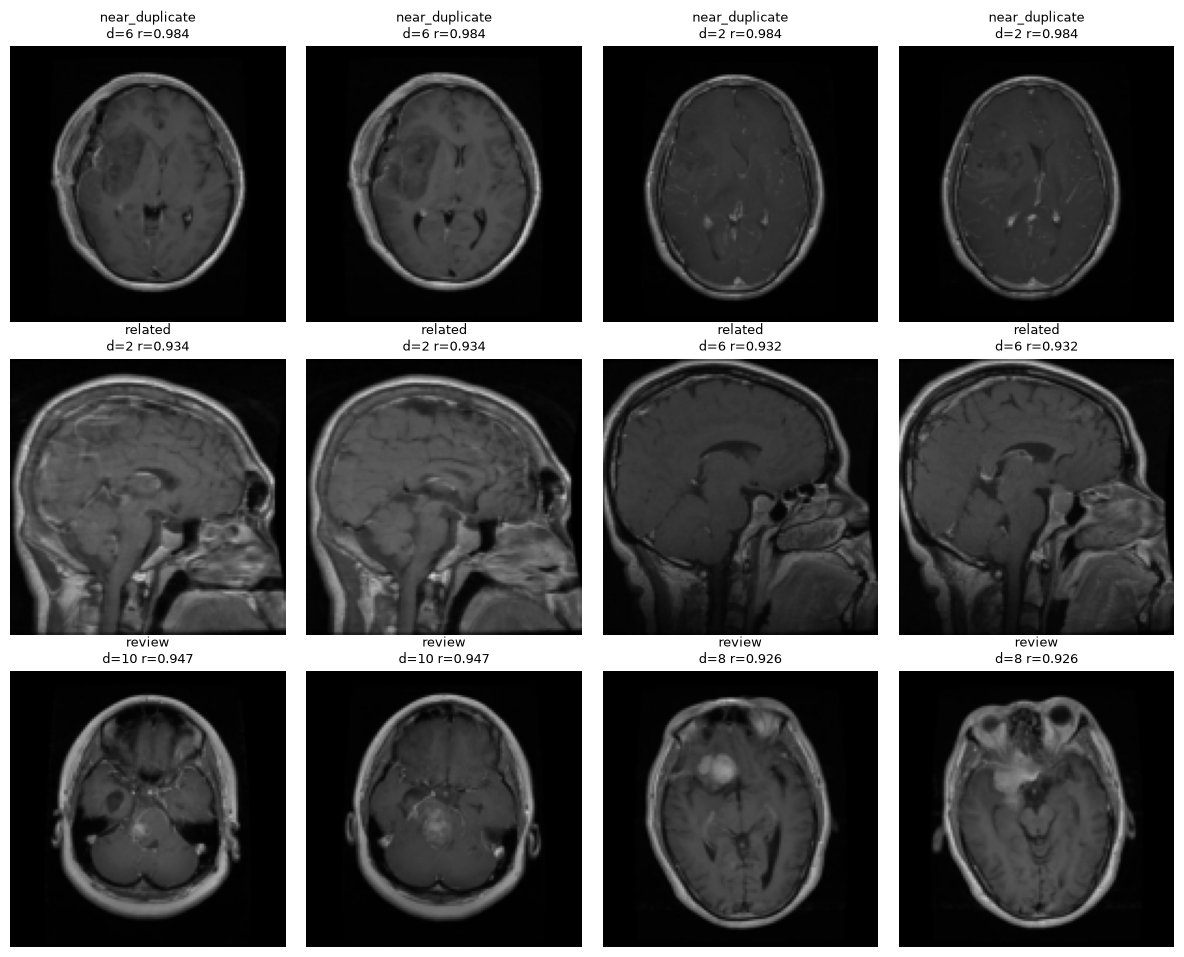

In [6]:
pairs = pd.read_csv(settings.manifests_dir / "similar_pairs.csv")
display(pairs.groupby("kind")[["hamming", "correlation"]].describe().round(3))
print("Pairs whose two images carry different labels:", int((~pairs["same_label"]).sum()))

lookup = samples.set_index("sample_id")
def image_path(sample_id):
    row = lookup.loc[sample_id]
    return settings.data_dir / row["split"] / row["label"] / Path(row["source_path"]).name

from src.preprocessing import PreprocessingSpec, load_image_file
spec = PreprocessingSpec.from_config(config)
rng = np.random.default_rng(0)
images, titles = [], []
for kind in ("near_duplicate", "related", "review"):
    subset = pairs[pairs["kind"] == kind]
    for _, pair in subset.iloc[rng.choice(len(subset), 2, replace=False)].iterrows():
        for side in ("first", "second"):
            images.append(load_image_file(image_path(pair[side]), spec))
            titles.append(f"{kind}\nd={pair['hamming']} r={pair['correlation']:.3f}")
plots.image_grid(images, titles, columns=4)

## 3. Split methodology

* Groups = an image plus every image linked to it (near-duplicate or related). A group is assigned
  to **one** split.
* **Retraining-demo batch first:** 25 images per class are reserved *before* initial training. Only
  singleton groups are eligible, so these images have no near-duplicate anywhere else. They are used later
  to demonstrate uploads and retraining with genuine labelled data.
* Remaining groups → train 70 % / validation 15 % / final test 15 %, stratified by `label|plane` with a
  greedy largest-group-first assignment (seed 42).
* Validation drives early stopping, model selection and promotion; the final test split is used once.

**Limitation:** there are no patient identifiers, so patient-level independence **cannot be
guaranteed**. Linking similar neighbouring slices reduces, but does not eliminate, that risk.

In [7]:
retained = samples[samples["status"] == "retained"]
display(pd.crosstab(retained["split"], retained["label"], margins=True))
display(pd.crosstab(retained["split"], retained["plane"]))
checks = {
    "linked groups spanning >1 split": int((retained.groupby("group_id")["split"].nunique() > 1).sum()),
    "identical-pixel images in >1 split": int((retained.groupby("pixel_hash")["split"].nunique() > 1).sum()),
    "retrain-demo images with any linked relative": int((retained.loc[retained["split"] == "retrain_demo", "group_size"] > 1).sum()),
    "near-duplicate/related pairs split apart": int(sum(lookup.loc[a, "split"] != lookup.loc[b, "split"]
                                                       for a, b in pairs.loc[pairs["kind"] != "review", ["first", "second"]].itertuples(index=False))),
}
pd.Series(checks).to_frame("count (must be 0)")

label,glioma,meningioma,no_tumor,pituitary,All
split,,,,,
retrain_demo,25,25,25,25,100
test,207,225,177,259,868
train,961,1044,818,1197,4020
validation,207,225,177,259,868
All,1400,1519,1197,1740,5856


plane,axial,coronal,sagittal
split,,,
retrain_demo,21,39,40
test,287,287,294
train,1329,1331,1360
validation,287,287,294


,count (must be 0)
linked groups spanning >1 split,0
identical-pixel images in >1 split,0
retrain-demo images with any linked relative,0
near-duplicate/related pairs split apart,0


## 4. Exploratory analysis (training split only)

Validation and test images are deliberately excluded from exploration.

Imbalance ratio (largest / smallest class): 1.46


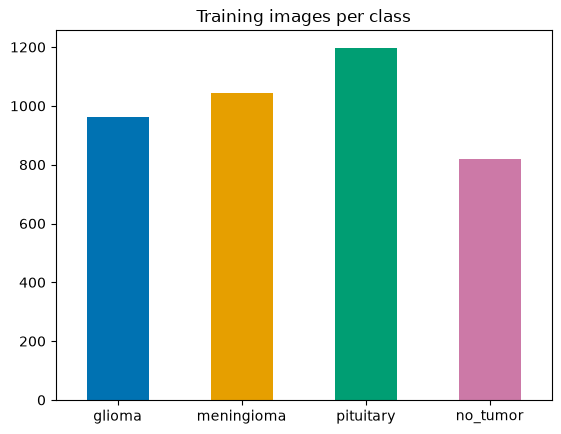

In [8]:
from src.dataset.manifests import load_arrays, read_split
train_samples = read_split(settings.data_dir, "train")
x_train, y_train = load_arrays(train_samples, spec, settings.cache_dir)
ax = pd.Series(np.bincount(y_train), index=CLASS_NAMES).plot.bar(title="Training images per class", rot=0, color=[plots.CLASS_COLOURS[c] for c in CLASS_NAMES])
print("Imbalance ratio (largest / smallest class):", round(np.bincount(y_train).max() / np.bincount(y_train).min(), 2))

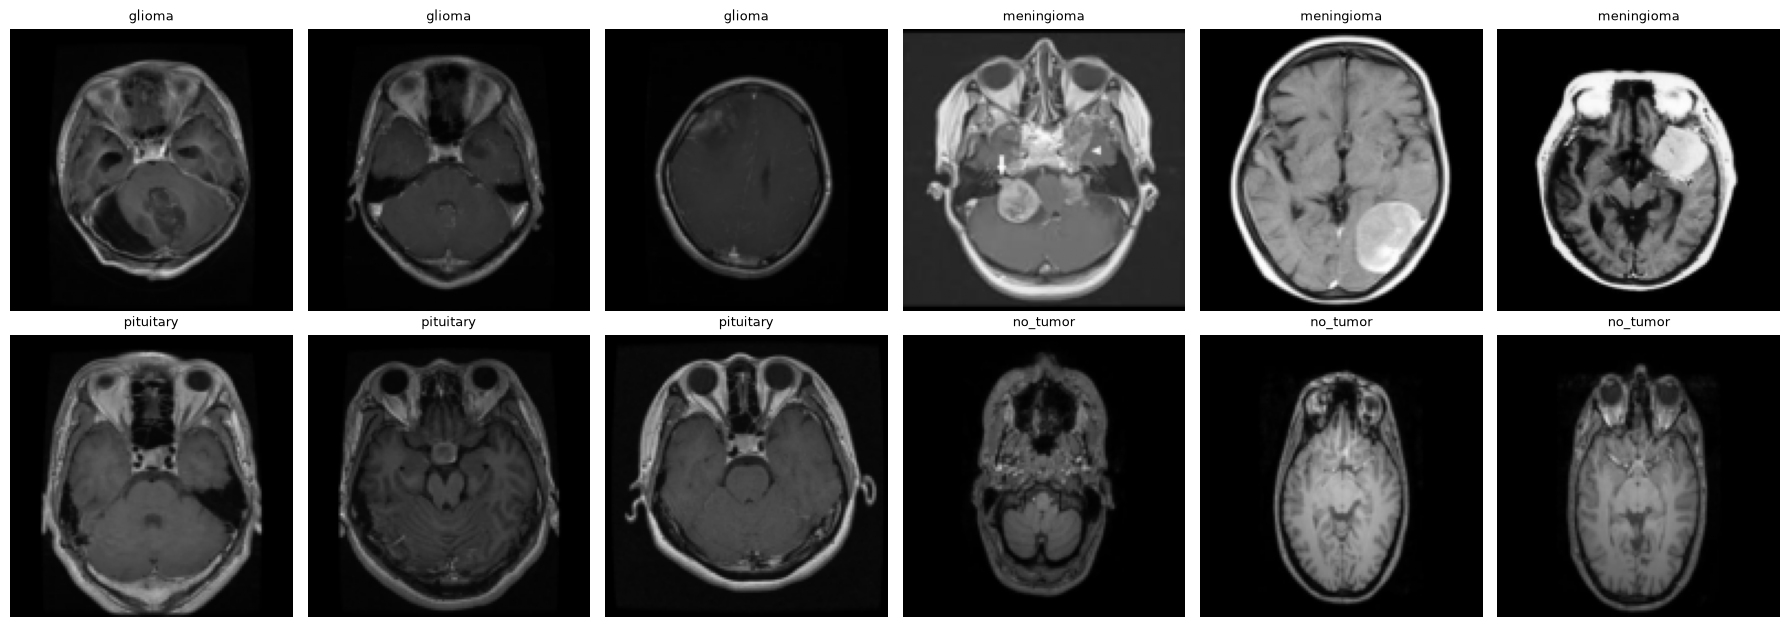

In [9]:
picks = [i for c in range(len(CLASS_NAMES)) for i in np.flatnonzero(y_train == c)[:3]]
plots.image_grid([x_train[i] for i in picks], [CLASS_NAMES[y_train[i]] for i in picks], columns=6)

### Image features

Measured on the standardized 128×128 images (`src/features.py`, `scripts/analyze_features.py`).
Brightness, contrast, texture and entropy use **foreground pixels only** (intensity > 20), so the
amount of black background does not masquerade as a tissue difference. Effect size is
Kruskal–Wallis ε² (0 = classes indistinguishable on that feature, 1 = perfectly separated); with
4,000 images every p-value is tiny, so ε² is the informative number.

,brightness,contrast,texture,entropy,foreground_fraction,whole_image_mean
class,,,,,,
glioma,68.01,27.66,13.64,4.52,0.46,32.45
meningioma,79.48,32.85,15.38,4.85,0.50,40.70
pituitary,73.52,29.19,14.16,4.63,0.65,49.54
no_tumor,88.53,34.43,18.20,4.96,0.46,41.59


,epsilon_squared
brightness,0.3294
foreground_fraction,0.3252
texture,0.2959
entropy,0.2956
whole_image_mean,0.2591
contrast,0.2439


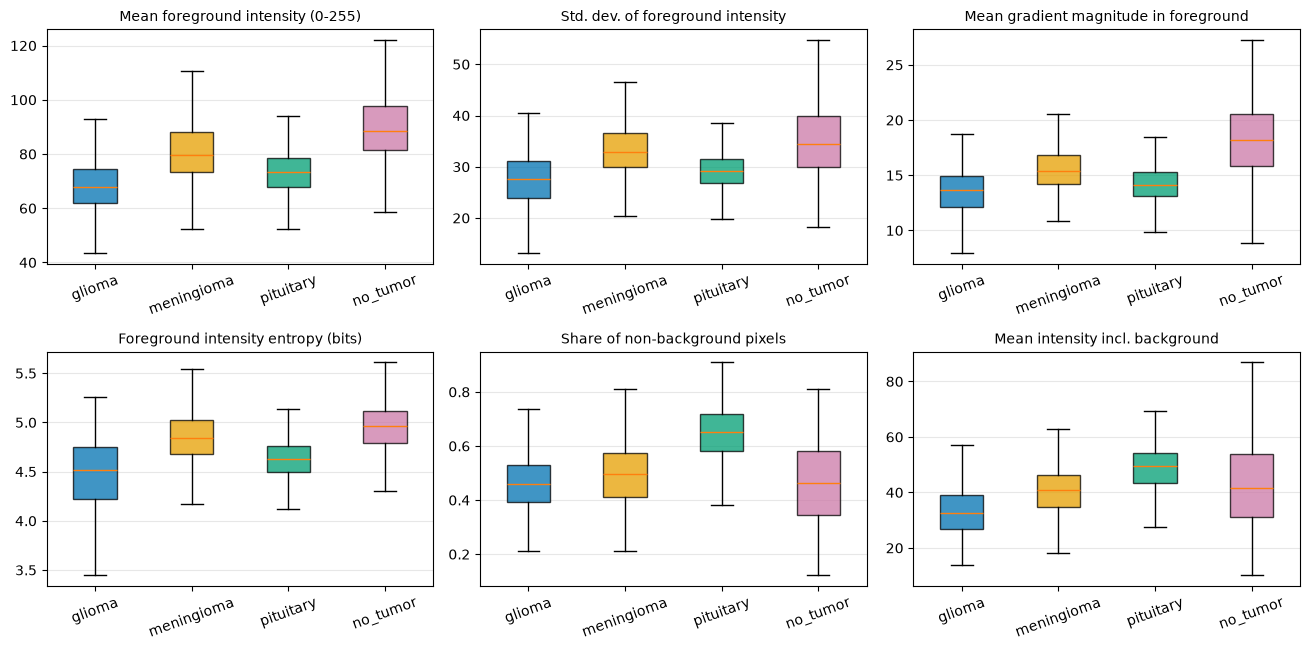

In [10]:
features = pd.read_csv(settings.reports_dir / "dataset" / "features.csv")
feature_summary = json.loads((settings.reports_dir / "dataset" / "feature_summary.json").read_text())
display(features.groupby("class")[list(feature_summary["features"])].median().loc[list(CLASS_NAMES)].round(2))
display(pd.DataFrame(feature_summary["class_separation"]).T[["epsilon_squared"]].sort_values("epsilon_squared", ascending=False))
plots.feature_boxplots(features, feature_summary["features"])

**What the measurements show (training split, 4,020 images).**

* **Brightness** (mean foreground intensity) is lowest for glioma (median ≈ 68) and highest for
  no-tumour (≈ 89), with pituitary (≈ 74) and meningioma (≈ 79) between; ε² ≈ 0.33, the largest
  separation of the tissue features.
* **Contrast** (foreground standard deviation) follows the same order (≈ 28 → 34; ε² ≈ 0.24), and so do
  **texture** (mean gradient magnitude, ≈ 13.6 → 18.2; ε² ≈ 0.30) and **entropy** (≈ 4.5 → 5.0 bits; ε² ≈ 0.30).
* **Foreground fraction** separates *pituitary* (median ≈ 0.65 of the frame is head) from the other
  classes (≈ 0.46–0.50; ε² ≈ 0.33): pituitary slices tend to be framed more tightly.

These are image statistics, not clinical findings. Overlap between classes is large (see the
boxplots), so no single feature classifies well — but together they show that simple global intensity
and framing statistics carry class information. That is a warning sign: a model can score well by
exploiting them instead of lesion anatomy. The next cell checks where they come from.

In [11]:
print("Source resolution by class (counts):")
display(pd.DataFrame(feature_summary["source_resolution_by_class"]).T)
print("Source aspect ratio by class (counts):")
display(pd.DataFrame(feature_summary["source_shape_by_class"]).T)
print("Median brightness by class and source resolution:")
pd.DataFrame(feature_summary["median_by_class_and_resolution"]["brightness"]).T

Source resolution by class (counts):


,512x512,other
glioma,961,0
meningioma,953,91
no_tumor,262,556
pituitary,1170,27


Source aspect ratio by class (counts):


,non_square,square
glioma,0,961
meningioma,83,961
no_tumor,295,523
pituitary,7,1190


Median brightness by class and source resolution:


,512x512,other
glioma,68.015,NaN
meningioma,78.662,106.883
no_tumor,97.974,86.665
pituitary,73.573,71.019


**Acquisition differences explain part of these patterns.** Planes are similarly mixed in every class,
so plane is not the explanation. Source geometry is: every training glioma image was stored at
512×512, versus about one third of no-tumour images (262 of 818); 295 of 818 no-tumour images are
non-square, against 0 glioma and 7 pituitary images. Within a class, brightness differs by source almost as
much as it differs between classes (no-tumour: ≈ 98 at 512×512 vs ≈ 87 otherwise; meningioma: ≈ 79 vs ≈ 107).
After letterboxing, non-square images also carry black side bars that other classes rarely have.

So part of the brightness/texture/framing differences reflects **which source collection an image came
from**, which is entangled with its label. This is a dataset property the model can learn as a
shortcut; §8 measures how strongly the trained model behaves that way.

## 5. Preprocessing

One deterministic function chain (`src/preprocessing.py`) is used by training, this notebook and the
API: decode by content → EXIF orientation → 8-bit greyscale → letterbox to a square with black borders
(keeps aspect ratio) → resize to 128×128 (bilinear) → scale to [0, 1]. The spec is stored in every
model's metadata and re-applied at inference.

Augmentation (`src/augmentation.py`) is applied **only to training batches**: horizontal flip, ±10°
rotation, ±10 % zoom, ±5 % shift, ±10 % contrast and brightness. Vertical flips are not used (they do not
correspond to a plausible acquisition). Validation/test batches are never augmented.

Example: brisc2025_test_00256_me_ax_t1 stored as RGB (228, 221)


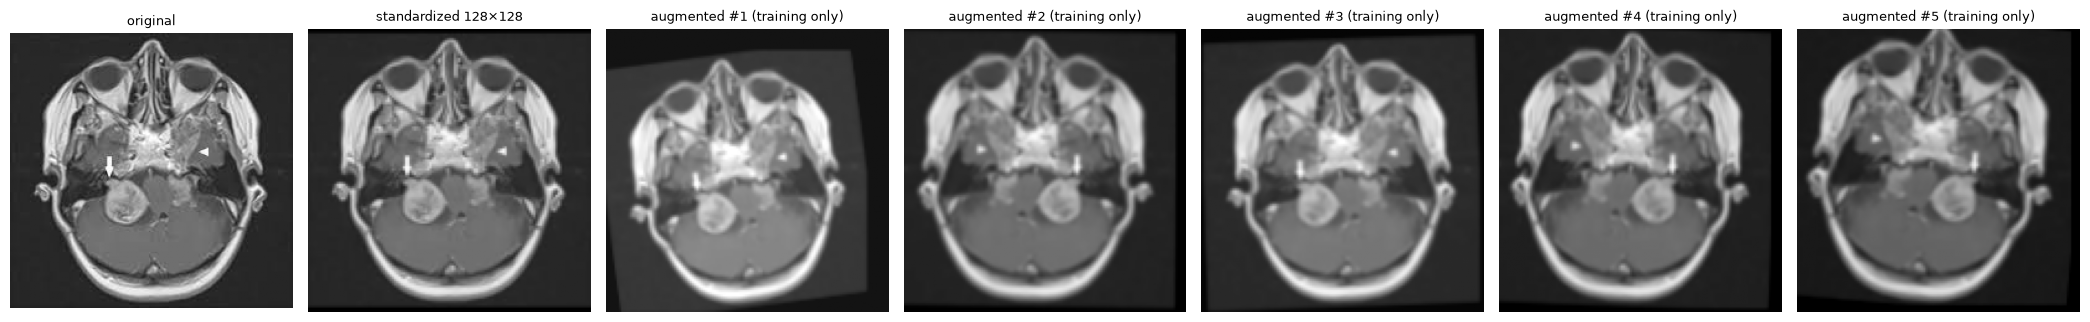

In [12]:
from PIL import Image
from src.augmentation import build_augmenter
from src.preprocessing import letterbox
wide = samples[(samples["status"] == "retained") & (samples["split"] == "train") & (samples["width"] != samples["height"])].iloc[0]
raw = Image.open(image_path(wide["sample_id"]))
print(f"Example: {wide['sample_id']} stored as {raw.mode} {raw.size}")
standardized = np.asarray(letterbox(raw, spec.image_size, spec.resample))
augmenter = build_augmenter(config, seed=1)
batch = np.repeat(standardized[None, ..., None].astype("float32") / 255.0, 5, axis=0)
augmented = np.clip(augmenter(batch, training=True).numpy(), 0, 1)
plots.image_grid([np.asarray(raw.convert("L")), standardized] + [(a[..., 0] * 255).astype("uint8") for a in augmented],
                 ["original", "standardized 128×128"] + [f"augmented #{i + 1} (training only)" for i in range(5)], columns=7)

In [13]:
print("Preprocessing spec saved with each model:", spec.to_dict())
print("Training array:", x_train.shape, x_train.dtype, "-> model input dtype float32 in [0, 1]")

Preprocessing spec saved with each model: {'image_size': 128, 'resample': 'bilinear', 'channels': 1, 'padding': 'letterbox-black', 'normalization': 'divide-by-255'}
Training array: (4020, 128, 128) uint8 -> model input dtype float32 in [0, 1]


## 6. Model creation

Both models are built in `src/model.py` from random initialisation.

* **Baseline** — Conv(16) → pool → Conv(32) → pool → global average → softmax (~5 k parameters).
  It shows what a minimal convolutional model achieves on this task.
* **Final CNN** — four blocks of [3×3 conv → batch norm → ReLU] ×2 + max-pool with 16/32/64/128 filters,
  global average pooling, dropout 0.3, softmax (~0.3 M parameters).

Why this design: stacked 3×3 convolutions reach a receptive field comparable to a lesion at 128 px;
batch norm makes training from scratch stable; global average pooling instead of large dense layers
keeps parameters low (less overfitting on ~4,000 images, fast CPU training and serving). A 4× wider
variant (32–256 filters, 1.2 M parameters) was timed at ~3.4× the cost per epoch on this CPU and was not
pursued. Loss: categorical cross-entropy with **class weights computed from training labels only**.

In [14]:
from src.model import build_model
for name in ("baseline", "cnn"):
    model = build_model(name, spec.image_size, 1e-3)
    print(f"{model.name}: {model.count_params():,} parameters")
build_model("cnn", spec.image_size, 1e-3).summary()

baseline_cnn: 4,932 parameters
brain_mri_cnn: 295,188 parameters


Model: "brain_mri_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ image (InputLayer)              │ (None, 128, 128, 1)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 (Conv2D)           │ (None, 128, 128, 16)   │           144 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_bn1 (BatchNormalization) │ (None, 128, 128, 16)   │            64 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_relu1 (Activation)       │ (None, 128, 128, 16)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, 128, 128, 16)   │         2,304 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_bn2 (BatchNormalization) │ (None, 128, 128, 16)   │            64 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_relu2 (Activation)       │ (None, 128, 128, 16)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 64, 64, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, 64, 64, 32)     │         4,608 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_bn1 (BatchNormalization) │ (None, 64, 64, 32)     │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_relu1 (Activation)       │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, 64, 64, 32)     │         9,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_bn2 (BatchNormalization) │ (None, 64, 64, 32)     │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_relu2 (Activation)       │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, 32, 32, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_bn1 (BatchNormalization) │ (None, 32, 32, 64)     │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_relu1 (Activation)       │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, 32, 32, 64)     │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_bn2 (BatchNormalization) │ (None, 32, 32, 64)     │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_relu2 (Activation)       │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv1 (Conv2D)           │ (None, 16, 16, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_bn1 (BatchNormalization) │ (None, 16, 16, 128)    │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_relu1 (Activation)       │ (None, 16, 16, 128)    │             

 Total params: 295,188 (1.13 MB)

 Trainable params: 294,228 (1.12 MB)

 Non-trainable params: 960 (3.75 KB)

## 7. Training

Training uses `src/training.py` via `src/pipeline.py`: Adam (lr 1e-3), batch 32, up to 40 epochs,
early stopping on **validation macro-F1** (patience 8, best weights restored), learning-rate halving on
validation-loss plateaus, balanced class weights. Every run is registered with its history,
configuration, class order, preprocessing spec, dataset version and a reload check of both the
`.keras` and `.h5` artifacts.

The cell below runs the **smoke mode** (tiny class-balanced subset, 2 epochs) to demonstrate the full
pipeline quickly into a scratch registry. The full models were trained beforehand with
`python scripts/train_model.py --architecture baseline` and `python scripts/train_model.py --activate`
(10 and 49 minutes on this CPU, while other work shared the machine); set `RUN_FULL_TRAINING = True` to retrain here.

In [15]:
from src.pipeline import load_training_data, run_training
RUN_FULL_TRAINING = False

training_data = load_training_data(settings, config)
smoke = run_training(training_data, config, ModelRegistry(settings.cache_dir / "notebook_smoke_registry"), smoke=True)
print(f"Smoke run registered as {smoke.version}: {smoke.outcome.epochs_run} epochs in {smoke.outcome.duration_seconds}s,",
      f"validation-subset macro-F1 {smoke.validation_metrics['macro_f1']:.3f} (meaningless by design; it only proves the pipeline runs)")
if RUN_FULL_TRAINING:
    full = run_training(training_data, config, registry)
    print("Registered", full.version, "(not activated)")

Smoke run registered as v004: 2 epochs in 42.7s, validation-subset macro-F1 0.196 (meaningless by design; it only proves the pipeline runs)


In [16]:
state = registry.state()
versions = pd.DataFrame.from_dict(state["versions"], orient="index")
display(versions)
ACTIVE = state["active"]
BASELINE = next(v for v, info in state["versions"].items() if info["architecture"] == "baseline")
meta = {v: registry.metadata(v) for v in (BASELINE, ACTIVE)}
for v in (BASELINE, ACTIVE):
    t = meta[v]["training"]
    print(f"{v} ({meta[v]['architecture']}): {t['epochs_run']} epochs, best epoch {t['best_epoch']}, {t['duration_seconds'] / 60:.1f} min, class weights {t['class_weights']}")

,registered_at,architecture,dataset_version,validation_macro_f1,job_id,status
v001,2026-11-21T10:08:36+00:00,baseline,brisc2025-clean-v1,0.678374,NaN,candidate
v002,2026-11-21T10:58:34+00:00,cnn,brisc2025-clean-v1,0.930197,NaN,active
v003,2026-11-21T12:32:50+00:00,cnn,brisc2025-clean-v1+uploads-4aecbec620,0.954795,a78ad55b9d65,previous


v001 (baseline): 40 epochs, best epoch 40, 10.0 min, class weights {'glioma': 1.0457856399583767, 'meningioma': 0.9626436781609196, 'pituitary': 0.8395989974937343, 'no_tumor': 1.228606356968215}
v002 (cnn): 24 epochs, best epoch 16, 49.1 min, class weights {'glioma': 1.0457856399583767, 'meningioma': 0.9626436781609196, 'pituitary': 0.8395989974937343, 'no_tumor': 1.228606356968215}


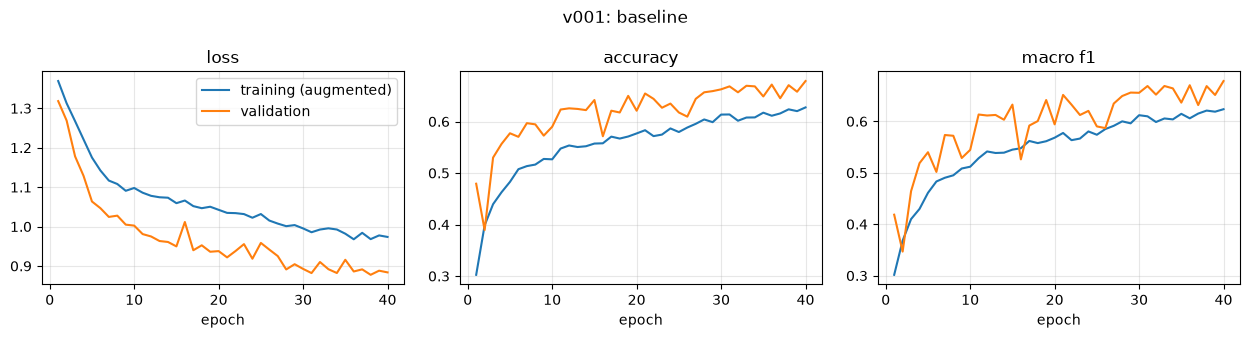

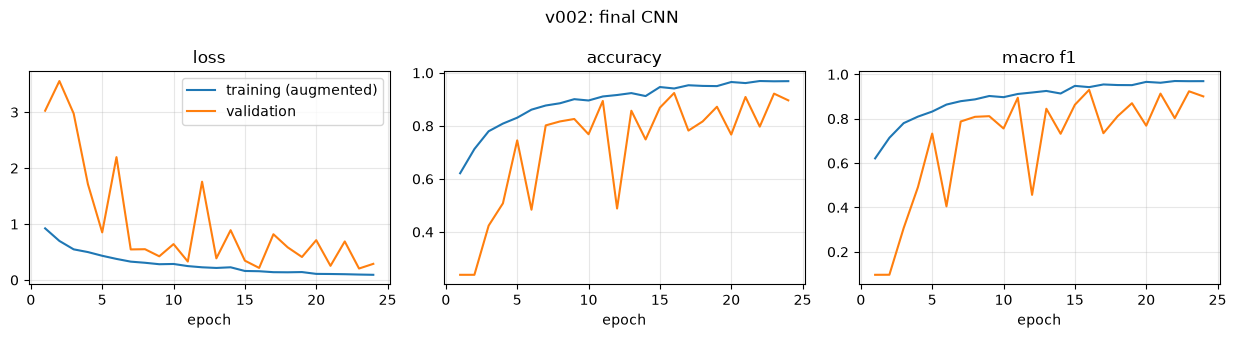

In [17]:
history = {v: json.loads((registry.version_dir(v) / "history.json").read_text()) for v in (BASELINE, ACTIVE)}
display(plots.training_curves(history[BASELINE], title=f"{BASELINE}: baseline"))
plots.training_curves(history[ACTIVE], title=f"{ACTIVE}: final CNN")

**Reading the curves.** Training accuracy (measured on augmented batches) rises steadily. Validation
is very unstable during the first ~15 epochs (accuracy as low as 0.24 at epochs 1–2 and sudden drops at
epochs 6 and 12). That pattern is typical of batch-normalised CNNs trained from scratch with a relatively
high learning rate: the running statistics used at evaluation time lag behind the fast-changing weights.
It settles after the learning rate is halved at epoch 15. Early stopping kept **epoch 16** (validation
macro-F1 0.930) and stopped at epoch 24 after eight epochs without improvement.

Choosing the best point of a noisy validation curve makes the validation score **optimistic**; that is
why the untouched test split (next section) is the number to report. The baseline improves slowly and
reaches validation macro-F1 0.678. It was still marginally improving at the 40-epoch cap, so a longer run
could add a little, but not close the gap.

## 8. Evaluation

Metrics (`src/evaluation.py`): accuracy, per-class precision/recall/F1 and support, macro and
weighted F1, confusion matrix — plus, with justification:

* **balanced accuracy** and **macro ROC-AUC (one-vs-rest)** — insensitive to class imbalance; AUC is
  threshold-free;
* **tumour sensitivity / specificity** — the UI's headline message is derived from the four-class
  output, so its binary error rates matter directly (a missed tumour is reported as "No tumor detected");
* **expected calibration error** — the UI displays a confidence score, so we check how well it matches
  observed accuracy.

Model selection used validation only. The final test split was evaluated **once**, after selection, with
`python scripts/evaluate_model.py --split test` (the script refuses to overwrite that report).

In [18]:
def headline(report):
    return {
        "accuracy": report["accuracy"], "balanced accuracy": report["balanced_accuracy"],
        "macro F1": report["macro_f1"], "weighted F1": report["weighted_f1"],
        "macro ROC-AUC": report.get("macro_roc_auc_ovr"), "log loss": report["log_loss"],
        "ECE": report["expected_calibration_error"],
        "tumour sensitivity": report["tumor_detection"]["sensitivity"],
        "tumour specificity": report["tumor_detection"]["specificity"],
    }

reports_dir = settings.reports_dir / "models"
test_report = json.loads((reports_dir / ACTIVE / "test_metrics.json").read_text())
baseline_test = json.loads((reports_dir / BASELINE / "test_metrics.json").read_text())
comparison = pd.DataFrame({
    f"baseline {BASELINE} — validation": headline(meta[BASELINE]["validation_metrics"]),
    f"CNN {ACTIVE} — validation": headline(meta[ACTIVE]["validation_metrics"]),
    f"baseline {BASELINE} — final test": headline(baseline_test),
    f"CNN {ACTIVE} — final test": headline(test_report),
}).round(4)
comparison

,baseline v001 — validation,CNN v002 — validation,baseline v001 — final test,CNN v002 — final test
accuracy,0.6786,0.9240,0.6325,0.8882
balanced accuracy,0.6726,0.9326,0.6250,0.8980
macro F1,0.6784,0.9302,0.6296,0.8952
weighted F1,0.6783,0.9247,0.6299,0.8897
macro ROC-AUC,0.8756,0.9953,0.8506,0.9923
log loss,0.8838,0.2164,0.9337,0.2820
ECE,0.1293,0.0193,0.0858,0.0312
tumour sensitivity,0.9479,0.9957,0.9407,0.9855
tumour specificity,0.7288,0.9944,0.6893,0.9774


,precision,recall,f1,support
glioma,0.954,0.903,0.928,207.0
meningioma,0.734,0.947,0.827,225.0
pituitary,0.995,0.764,0.865,259.0
no_tumor,0.945,0.977,0.961,177.0


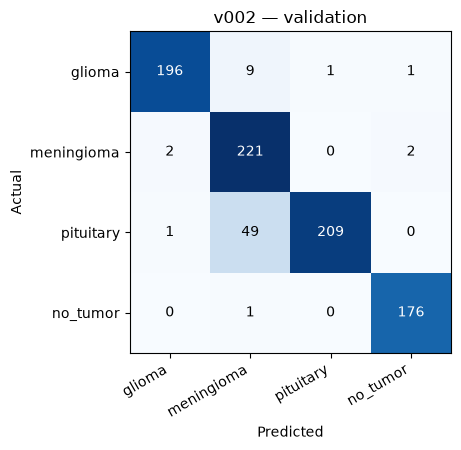

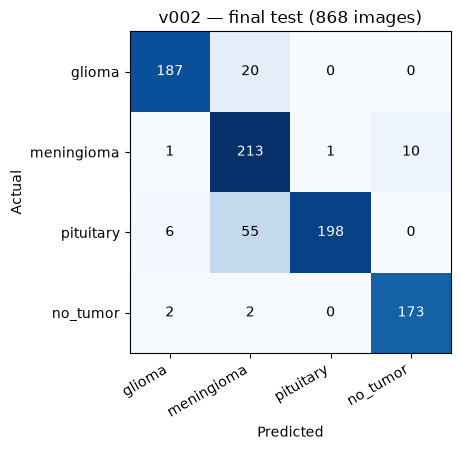

In [19]:
per_class = pd.DataFrame(test_report["per_class"]).T.loc[list(CLASS_NAMES)]
display(per_class.round(3))
display(plots.confusion_matrix(meta[ACTIVE]["validation_metrics"]["confusion_matrix"], f"{ACTIVE} — validation"))
plots.confusion_matrix(test_report["confusion_matrix"], f"{ACTIVE} — final test ({test_report['samples']} images)")

**Results (final test, 868 images, evaluated once).** The CNN reaches accuracy **0.888**, macro-F1
**0.895**, weighted F1 0.890, balanced accuracy 0.898 and macro ROC-AUC 0.992. The baseline reaches
0.632 accuracy and 0.630 macro-F1, so depth and capacity clearly matter here. Validation was higher
(macro-F1 0.930), consistent with the optimistic model selection described above.

* **Main error: pituitary → meningioma** (55 of 259 pituitary test slices; 49 of 259 on validation).
  Pituitary precision is very high (0.995) but recall is 0.764. Meningioma absorbs these errors (recall
  0.947, precision 0.734), and 20 glioma slices are also called meningioma.
* **Derived tumour status:** sensitivity 0.986 and specificity 0.977. All 10 false negatives (tumour shown as
  "No tumor detected") are meningioma slices; there are 4 false positives.
* **Calibration:** ECE 0.031 — on average the score tracks accuracy. But 15 of the 97 errors carry
  confidence above 0.9, so a high score does not guarantee a correct answer.

### Does the model rely on acquisition shortcuts?

Section 4 showed that non-square, non-512×512 source images are concentrated in `no_tumor`. If the model
used the resulting letterbox bars as a cue, accuracy would differ sharply between square and non-square
images *within the same class*. The test predictions are split by source geometry below.

In [20]:
from src.features import acquisition_metadata
predictions = pd.read_csv(reports_dir / ACTIVE / "test_predictions.csv").merge(
    acquisition_metadata(settings.manifests_dir / "samples.csv"), on="sample_id")
predictions["correct"] = predictions["label"] == predictions["predicted"]
shortcut = predictions.groupby(["label", "source_shape"]).agg(images=("correct", "size"), accuracy=("correct", "mean"),
    predicted_no_tumor=("predicted", lambda p: (p == "no_tumor").mean())).round(3)
display(shortcut)
predictions.groupby(["label", "source_resolution"]).agg(images=("correct", "size"), accuracy=("correct", "mean")).round(3)

images  accuracy  predicted_no_tumor
label      source_shape                                      
glioma     square           207     0.903               0.000
meningioma non_square        20     0.750               0.250
           square           205     0.966               0.024
no_tumor   non_square        61     0.984               0.984
           square           116     0.974               0.974
pituitary  square           259     0.764               0.000

images  accuracy
label      source_resolution                  
glioma     512x512               207     0.903
meningioma 512x512               194     0.979
           other                  31     0.742
no_tumor   512x512                60     0.950
           other                 117     0.991
pituitary  512x512               250     0.764
           other                   9     0.778

**Finding: the model partly relies on acquisition shortcuts.** Among test meningioma slices, **25.8 %
of the 31 from non-512×512 sources are predicted `no_tumor`, against 1.0 % of the 194 at 512×512**
(by aspect ratio: 25 % of non-square vs 2.4 % of square). That small subgroup produces **8 of the 10**
missed tumours. Conversely, `no_tumor` slices are recognised slightly better when they come from the
non-512 sources (0.991 vs 0.950).

This matches the training-data confound in §4: the model has learned that "looks like the other source
collection" correlates with `no_tumor`. Source and difficulty may also be entangled, so this is strong
evidence rather than proof of a shortcut. Either way, accuracy on images from other scanners or hospitals
is unknown and likely lower than the test score suggests. Possible mitigations, not implemented: randomised
crop/padding so letterbox bars carry no signal, source-balanced sampling, and validation on an external
dataset.

## 9. Prediction functions

`src/prediction.Predictor` is the exact code path the API uses: it loads a registered model with its
metadata and input-gate calibration, refuses a mismatched class order, applies the stored preprocessing,
checks the input, and then either returns the class, derived message and confidence, or **refuses** the
image with reasons and no class at all (§9b).

In [21]:
from src.prediction import Predictor
predictor = Predictor.from_registry(registry, config)
test_manifest = pd.read_csv(settings.manifests_dir / "test.csv")
rows = []
for name in CLASS_NAMES:
    sample = test_manifest[test_manifest["label"] == name].iloc[0]
    result = predictor.predict_bytes((settings.data_dir / sample["path"]).read_bytes())
    rows.append({"file": Path(sample["path"]).name, "true": name, "accepted": result.accepted, "predicted": result.predicted_class,
                 "message": result.message, "confidence": result.confidence, "feature distance": result.feature_distance})
pd.DataFrame(rows)

,file,true,accepted,predicted,message,confidence,feature distance
0,brisc2025_test_00007_gl_ax_t1.jpg,glioma,True,glioma,Tumor detected — predicted type: glioma.,0.9819,7.28
1,brisc2025_test_00263_me_ax_t1.jpg,meningioma,True,no_tumor,No tumor detected in this image.,0.9822,14.38
2,brisc2025_test_00705_pi_ax_t1.jpg,pituitary,True,meningioma,Tumor detected — predicted type: meningioma.,0.4500,10.26
3,brisc2025_test_00563_no_ax_t1.jpg,no_tumor,True,no_tumor,No tumor detected in this image.,0.9971,9.59


In [22]:
# The .h5 deliverable: reload it and confirm it reproduces the served .keras model's outputs.
from src.evaluation import predict_probabilities
from src.registry import H5_FILE, KERAS_FILE
x_test, y_test = load_arrays(read_split(settings.data_dir, "test"), spec, settings.cache_dir)
probs_keras = predict_probabilities(registry.load_model(ACTIVE, KERAS_FILE), x_test)
probs_h5 = predict_probabilities(registry.load_model(ACTIVE, H5_FILE), x_test)
print(f".h5 vs .keras on {len(x_test)} test images: max |Δp| = {np.abs(probs_h5 - probs_keras).max():.2e},",
      f"identical predicted classes: {(probs_h5.argmax(1) == probs_keras.argmax(1)).all()}")
print("Artifact files:", {f.name: f"{f.stat().st_size / 1e6:.1f} MB" for f in registry.version_dir(ACTIVE).glob('model.*')})

.h5 vs .keras on 868 test images: max |Δp| = 0.00e+00, identical predicted classes: True
Artifact files: {'model.h5': '3.7 MB', 'model.keras': '3.7 MB'}


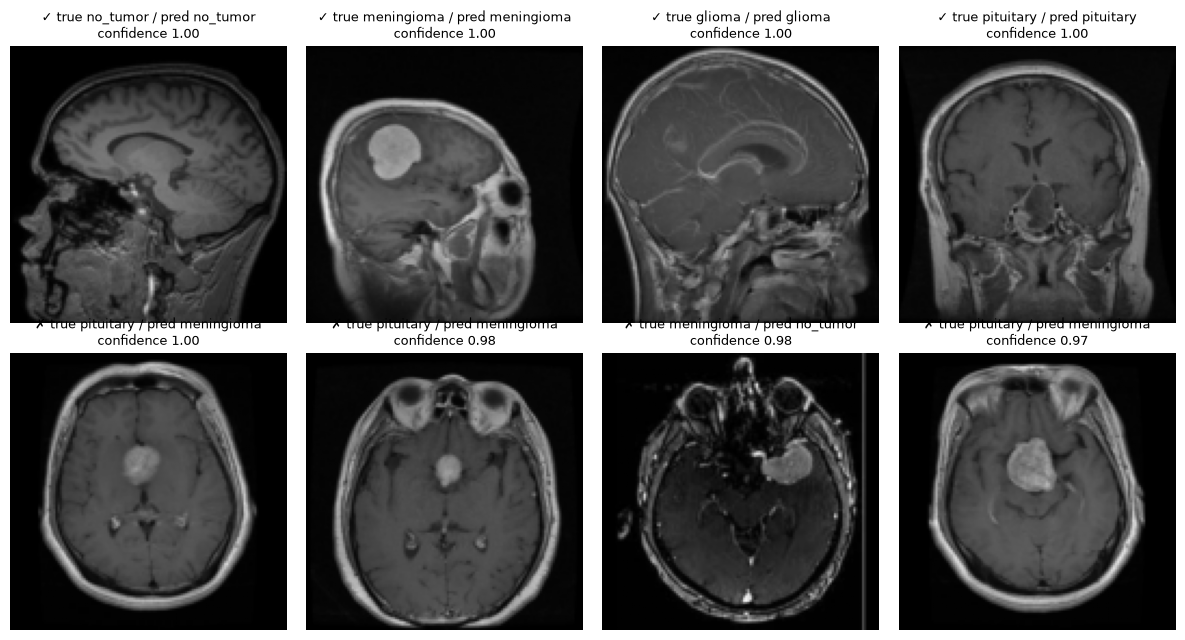

In [23]:
predictions["index"] = range(len(predictions))
correct = predictions[predictions["correct"]].sort_values("confidence", ascending=False).groupby("label").head(1)
wrong = predictions[~predictions["correct"]].sort_values("confidence", ascending=False).head(4)
chosen = pd.concat([correct, wrong])
plots.image_grid([x_test[i] for i in chosen["index"]],
                 [f"{'✓' if ok else '✗'} true {t} / pred {p}\nconfidence {c:.2f}" for ok, t, p, c in chosen[["correct", "label", "predicted", "confidence"]].itertuples(index=False)],
                 columns=4)

Correct predictions (✓, one per class) have confidence ≥ 0.999. The four most confident errors (✗) are
three pituitary slices called meningioma (confidence 0.97–0.997) and one meningioma slice called
`no_tumor` with confidence 0.98 — a 200×223 image from a non-512 source, i.e. the subgroup affected by the
shortcut above. A high confidence score is therefore not a guarantee of a correct answer.

### 9b. Input gate: refusing images that do not look like training MRIs

A four-class softmax always picks *some* class, so an unrelated photo can be labelled "meningioma, 100 %".
Before classifying, the predictor therefore checks the input (`src/input_gate.py`) and **withholds any
class, score or tumour message** if a check fails:

* **Rules** (thresholds from the BRISC data, `config/pipeline.yaml`): colour image (every BRISC file is
  greyscale), aspect ratio > 2.5 (widest BRISC slice 1.97), near-uniform image (flattest BRISC slice has std
  19.9), bright border (MRI backgrounds are black; only 2 of 5,856 real slices exceed the limit).
* **Feature distance:** Mahalanobis distance of the CNN's penultimate features to the nearest training-class
  mean (shared Ledoit–Wolf covariance, no pretrained parts). The threshold is the 99th percentile of real
  *validation* MRIs, so about 1 % of genuine slices are refused by design. Each model version stores its own
  calibration; new models are calibrated automatically when registered.

The tables below come from `scripts/calibrate_input_gate.py` (threshold from validation; test and probe
images only measured).

In [24]:
gate_report = json.loads((settings.reports_dir / "input_gate" / f"{ACTIVE}.json").read_text())
print("Feature-distance threshold:", gate_report["calibration"]["threshold"])
display(pd.DataFrame(gate_report["real_mri_refusals"]).T.fillna(0))
display(pd.DataFrame(gate_report["probes"])[["probe", "expected", "outcome", "feature_distance"]])

# Live check through the same code path as the API: an unrelated greyscale photo vs. a brain MRI from another source.
import gzip, io
import matplotlib
from PIL import Image
sample_data = Path(matplotlib.get_data_path()) / "sample_data"
def png(image):
    buffer = io.BytesIO(); image.save(buffer, format="PNG"); return buffer.getvalue()
raw = np.frombuffer(gzip.open(sample_data / "s1045.ima.gz").read(), dtype=">u2").reshape(256, 256).astype(float)
live = {
    "greyscale portrait photo": png(Image.open(sample_data / "grace_hopper.jpg").convert("L")),
    "brain MRI from another source": png(Image.fromarray((raw / raw.max() * 255).astype(np.uint8))),
}
pd.DataFrame([{"image": name, "accepted": r.accepted, "message": r.message, "predicted": r.predicted_class,
               "feature distance": r.feature_distance, "reasons": r.rejection_reasons}
              for name, r in ((name, predictor.predict_bytes(data)) for name, data in live.items())])

Feature-distance threshold: 17.1634


,images,accepted,refused: feature distance,refused: rules,refused_fraction
validation,868.0,859.0,8.0,1.0,0.0104
test,868.0,863.0,5.0,0.0,0.0058
retrain_demo,100.0,100.0,0.0,0.0,0.0000


,probe,expected,outcome,feature_distance
0,"portrait photo, colour",refuse,refused: rules,NaN
1,"portrait photo, greyscale",refuse,refused: feature distance,20.92
2,product photo,refuse,refused: rules,NaN
3,matplotlib logo,refuse,refused: rules,NaN
4,terrain elevation map,refuse,refused: feature distance,20.77
5,random noise,refuse,refused: rules,NaN
6,dark random noise,refuse,refused: rules,NaN
7,blank grey image,refuse,refused: rules,NaN
8,brain MRI from another source (matplotlib s1045),accept,accepted,9.59
9,BRISC test slice rotated 90 degrees,accept,accepted,7.06


,image,accepted,message,predicted,feature distance,reasons
0,greyscale portrait photo,False,"This doesn't look like a brain MRI slice, so no prediction is shown.",NaN,20.92,[It does not resemble the MRI slices the model was trained on (feature distance 20.9 > 17.2).]
1,brain MRI from another source,True,No tumor detected in this image.,no_tumor,9.59,[]


**Reading the result.** The served model refuses every non-MRI probe and accepts both MRIs that are not
from BRISC, while refusing about 1 % of real validation slices. Those refusals are **not evenly spread**:
on the test split, 4 of the 31 meningioma slices from the minority non-512×512 sources are refused (0 of 194
at 512×512) — the same under-represented subgroup behind the shortcut in §8. The gate lowers the risk of
confident nonsense on unrelated images; it cannot prove that an accepted image is a brain MRI.

## 10. Limitations

* **Not a diagnostic tool.** Single 2-D slices, four classes only; real diagnosis uses full volumes,
  multiple sequences, clinical context and expert review.
* **Patient independence is not guaranteed** — the dataset has no patient identifiers. Exact duplicates
  are removed and near-duplicates / neighbouring slices are kept in one split, but other slices of the
  same patient may still appear in both training and test, which can inflate test scores.
* **Acquisition confound.** Source resolution and aspect ratio differ strongly by class (most
  non-square / non-512 images are `no_tumor`). See §8 for how much the model appears to depend on it;
  results on images from other scanners or hospitals are unknown and likely worse.
* **Labels** are taken as provided; clinical label accuracy was not independently verified.
* **Out-of-scope inputs.** The input gate (§9b) refuses colour, blank, bright-bordered and feature-distant
  images instead of labelling them, but it cannot prove an accepted image is a brain MRI, and about 1 % of
  genuine slices — more for under-represented sources — are refused.
* **Confidence ≠ probability of being correct**; see the calibration error above.
* **Retraining** on user uploads relies on user-assigned labels that still need trustworthy review.
* **Licence:** BRISC is published under CC BY 4.0 on Kaggle; upstream source-collection terms were not
  individually verified (README).

## 11. Reproducibility

```powershell
python -m venv .venv; .\.venv\Scripts\Activate.ps1
python -m pip install -r requirements.txt
python scripts/prepare_dataset.py --archive "C:\path\to\brisc2025.zip"   # seed 42, config/pipeline.yaml
python scripts/train_model.py --smoke                                     # quick pipeline check
python scripts/train_model.py --architecture baseline                     # baseline
python scripts/train_model.py --activate                                  # final CNN, served model
python scripts/evaluate_model.py --split test                             # final test, once
python scripts/evaluate_model.py --split test --version <baseline version>
python scripts/analyze_features.py
jupyter nbconvert --to notebook --execute --inplace notebook/brain_mri_classifier.ipynb
```

Seeds are fixed (data split, shuffling, augmentation, initialisation), but TensorFlow on CPU with oneDNN
is not bit-for-bit deterministic, so retraining gives close but not identical numbers.

## Rubric update: continuing our own trained model (2026-11-22)
Initial model creation above uses random weights. The background worker now loads the active custom CNN from the trusted registry and continues training its weights on the original training split plus reviewed uploads. It creates a fresh Adam optimizer at learning rate 0.0001. All layers remain trainable.
Candidates record parent_version, parent artifact checksum and training.initialization = saved_custom_weights. The saved parent is unchanged. The full fixed validation split controls promotion; final-test data is excluded. Smoke jobs never promote.
The existing notebook outputs and v003 historical retraining results predate this workflow update; they are not new fine-tuning results. See tests/test_retraining.py for the test of identical parent weights at fit entry, changed candidate weights after training, and an unchanged saved parent.
For the video: camera on, clear sound, correct labelled prediction, uploaded files plus SQLite records, preprocessing, and a completed retraining job showing its parent model.
Verified on 2026-11-22: 71 tests passed. A separate local worker loaded v002 and ran one full-data epoch with one admitted retrain-demo image (4,021 train / 868 validation). Validation macro-F1 was 0.8766, below the parent 0.9302; promotion was refused. Parent artifacts were unchanged. Both candidate formats reloaded. This was an isolated workflow check, not a new final-test evaluation; see reports/retraining_demo/saved_weights_check.json.
